# Confusion matrix and annotation quality
This notebook makes two confusion matrices and calculates the precision, recall and F1 of gpt annotation per class. The two confusion matrices are:
1. gpt vs human annotation. How do human and gpt annotation differ?
2. annotation class co-occurance in human annotation. Humans could give one word multiple semantic classes. This matrix shows how much different annotation classes co-occur with each other.

## Prepwork

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, recall_score, f1_score

In [16]:
gold_path = "C:\\Users\\kertu.saul\\OneDrive - Eesti Keele Instituut\\Dokumendid\\doktoritoo\\estnltk_syntax_repo_kloon\\physical_location_labelling\\physical_location_by_context\\v07_all_types_goldstandard\\results\\manual_annotation_Andriela.xlsx"
df_human = pd.read_excel(gold_path, sheet_name="Andriela_annotation")
df_gpt = pd.read_excel(gold_path, sheet_name="LLM_annotation")

In [17]:
df_gpt.head()

,sentence_id,head_id,head_loc,verb,verb_compound,morph_case,lemma,form,sentence,tags,...,ekilex_tag,ner_tag,A,E,T,L1,L2,L,S,tag
0,10773339,17257273,11,koonduma,NaN,adit,keskarvutis,keskarvutisse,Igale lossis olevale uksele pannakse magnetluk...,NaN,...,NaN,NaN,no,no,no,yes,no,yes,no,L
1,6117206,9818182,9,lõppema,NaN,el,suvi,suvest,""" Seevastu vanemates klassides lõppeb kool nii...",|T|AT|ET|LT|ST|AET|ALT|AST|ELT|LST|,...,time,NaN,no,no,yes,no,no,no,no,T
2,6466678,10398441,12,kestma,NaN,all,tänav,tänavale,Kuna tegemist on suuremõõtmelise eriveosega ke...,|L|AL|EL|LS|LT|ALT|ELT|LST|,...,location,NaN,no,no,no,yes,no,yes,no,L
3,2479356,3975787,14,tähistama,NaN,all,tase,tasemele,Väidetavalt olevat presidendi julgeolekunõunik...,NaN,...,NaN,NaN,no,no,no,yes,no,yes,no,L
4,9612010,15428229,4,laiutama,NaN,ad,sadamaala,sadamaalal,Praegu aga laiutab sadamaalal kena roheline lo...,NaN,...,NaN,NaN,no,no,no,yes,no,yes,no,L


In [19]:
# makes the annotation labels the same in gpt and human annotation
df_human = df_human.replace([0, "x"], ["no", "yes"])
df_human.head()

,sentence_id,head_id,head_loc,verb,verb_compound,morph_case,lemma,form,sentence,elus,valdaja,sündmus,aeg,füüsiline koht,abstraktne koht,koht,seisund,viga,kommentaar
0,10773339,17257273,11,koonduma,NaN,adit,keskarvutis,keskarvutisse,Igale lossis olevale uksele pannakse magnetluk...,no,no,no,no,no,yes,yes,no,yes,NaN
1,6117206,9818182,9,lõppema,NaN,el,suvi,suvest,""" Seevastu vanemates klassides lõppeb kool nii...",no,no,no,yes,no,no,no,no,no,NaN
2,6466678,10398441,12,kestma,NaN,all,tänav,tänavale,Kuna tegemist on suuremõõtmelise eriveosega ke...,no,no,no,no,yes,no,yes,no,no,NaN
3,2479356,3975787,14,tähistama,NaN,all,tase,tasemele,Väidetavalt olevat presidendi julgeolekunõunik...,no,no,no,no,no,yes,yes,no,yes,teise verbi alluv
4,9612010,15428229,4,laiutama,NaN,ad,sadamaala,sadamaalal,Praegu aga laiutab sadamaalal kena roheline lo...,no,no,no,no,yes,no,yes,no,no,NaN


## Human vs LLM annotation

In [20]:
#create confusion matrix
human_cols = ['elus', 'sündmus', 'aeg', 'füüsiline koht', 'abstraktne koht', 'koht', 'seisund', 'valdaja', 'viga']
gpt_cols = ['A', 'E', 'T', 'L1', 'L2', 'L', 'S']

# Initialize 3x3 confusion matrix
cm = pd.DataFrame(
    0,
    index=human_cols + ['other'],
    columns=gpt_cols + ['O']
)

# Compare every human category with every LLM category
for human_col, human_label in zip(human_cols, cm.index):
    for gpt_col, gpt_label in zip(gpt_cols, cm.columns):

        cm.loc[human_label, gpt_label] = (
            (df_human[human_col].str.lower() == 'yes') &
            (df_gpt[gpt_col].str.lower() == 'yes')
        ).sum()

# Count rows where ALL human categories have no annotation
human_other = (
    df_human[human_cols]
    .apply(lambda row: row.str.lower().eq('no').all(), axis=1)
)

# Count rows where ALL GPT categories have no annotation
gpt_other = (
    df_gpt[gpt_cols]
    .apply(lambda row: row.str.lower().eq('no').all(), axis=1)
)

# Human Other vs GPT categories
for gpt_col in gpt_cols:
    cm.loc['other', gpt_col] = (
        human_other &
        (df_gpt[gpt_col].str.lower() == 'yes')
    ).sum()

# Human categories vs GPT Other
for human_col in human_cols:
    cm.loc[human_col, 'O'] = (
        (df_human[human_col].str.lower() == 'yes') &
        gpt_other
    ).sum()

# Both human and GPT classified as Other
cm.loc['other', 'O'] = (
    human_other & gpt_other
).sum()


cm['Total'] = cm.sum(axis=1)

In [21]:
cm

,A,E,T,L1,L2,L,S,O,Total
elus,134,0,0,4,0,4,0,3,145
sündmus,0,63,0,0,2,2,0,2,69
aeg,0,31,47,0,0,0,0,0,78
füüsiline koht,1,70,3,195,1,196,0,3,469
abstraktne koht,2,15,2,86,12,98,1,7,223
koht,3,85,5,281,13,294,1,10,692
seisund,0,2,2,2,1,3,7,0,17
valdaja,82,1,0,32,4,36,1,15,171
viga,22,22,10,55,7,62,7,49,234
other,3,18,4,49,19,68,18,105,284


In [26]:
cm = cm.drop("Total", axis=1)

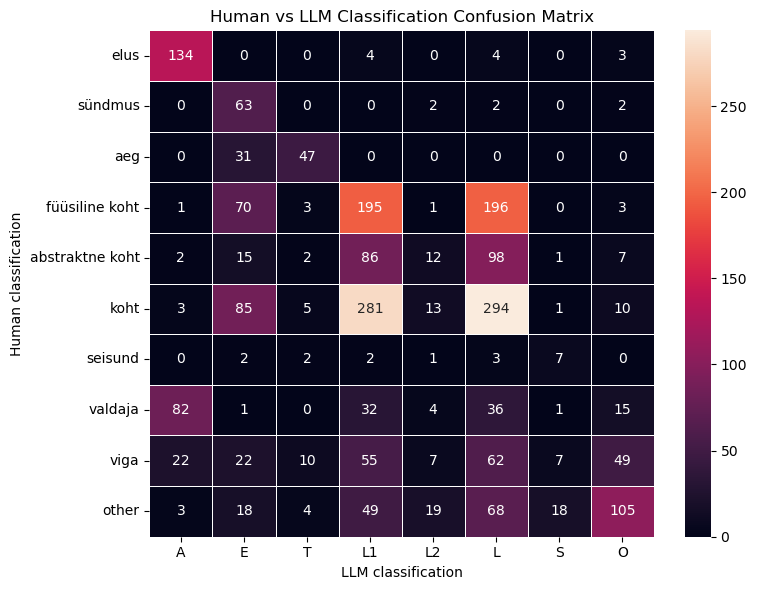

In [27]:
# Plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    linewidths=0.5,
    cbar=True
)

plt.xlabel('LLM classification')
plt.ylabel('Human classification')
plt.title('Human vs LLM Classification Confusion Matrix')

plt.tight_layout()
plt.show()

In [25]:
#calculate precision, recall, f1
results = []

for human_col, gpt_col in zip(human_cols, gpt_cols):

    y_true = (df_human[human_col].str.lower() == 'yes')
    y_pred = (df_gpt[gpt_col].str.lower() == 'yes')

    results.append({
        'Class': human_col,
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0)
    })

metrics_df = pd.DataFrame(results)

print(metrics_df.round(3))

             Class  Precision  Recall     F1
0             elus      0.937   0.950  0.944
1          sündmus      0.394   0.940  0.555
2              aeg      0.746   0.603  0.667
3   füüsiline koht      0.515   0.714  0.598
4  abstraktne koht      0.273   0.096  0.142
5             koht      0.695   0.739  0.716
6          seisund      0.212   0.500  0.298


## Annotation class co-occurance in human annotation
In the human annotation, one word can have multiple classes. This calculates how much each class co-occured together

In [22]:
#create confusion matrix
human_cm = pd.DataFrame(
    0,
    index=human_cols + ['other'],
    columns=human_cols + ['other']
)

# Count co-occurrences
for human_col1 in human_cols:
    for human_col2 in human_cols:

        human_cm.loc[human_col1, human_col2] = (
            (df_human[human_col1].str.lower() == 'yes') &
            (df_human[human_col2].str.lower() == 'yes')
        ).sum()

# Identify Other (all three main categories are no)
human_other = (
    df_human[human_cols]
    .apply(lambda row: row.str.lower().eq('no').all(), axis=1)
)

# Count Other co-occurrences
for human_col in human_cols:
    human_cm.loc['other', human_col] = (
        human_other &
        (df_human[human_col].str.lower() == 'yes')
    ).sum()

    human_cm.loc[human_col, 'other'] = (
        human_other &
        (df_human[human_col].str.lower() == 'yes')
    ).sum()

human_cm.loc['other', 'other'] = human_other.sum()

In [23]:
human_cm

,elus,sündmus,aeg,füüsiline koht,abstraktne koht,koht,seisund,valdaja,viga,other
elus,141,0,0,0,2,2,0,80,27,0
sündmus,0,67,4,35,9,44,0,0,7,0
aeg,0,4,78,0,0,0,0,0,5,0
füüsiline koht,0,35,0,273,0,273,0,0,34,0
abstraktne koht,2,9,0,0,125,125,0,0,14,0
koht,2,44,0,273,125,398,0,0,48,0
seisund,0,0,0,0,0,0,14,0,2,0
valdaja,80,0,0,0,0,0,0,135,19,0
viga,27,7,5,34,14,48,2,19,172,0
other,0,0,0,0,0,0,0,0,0,216


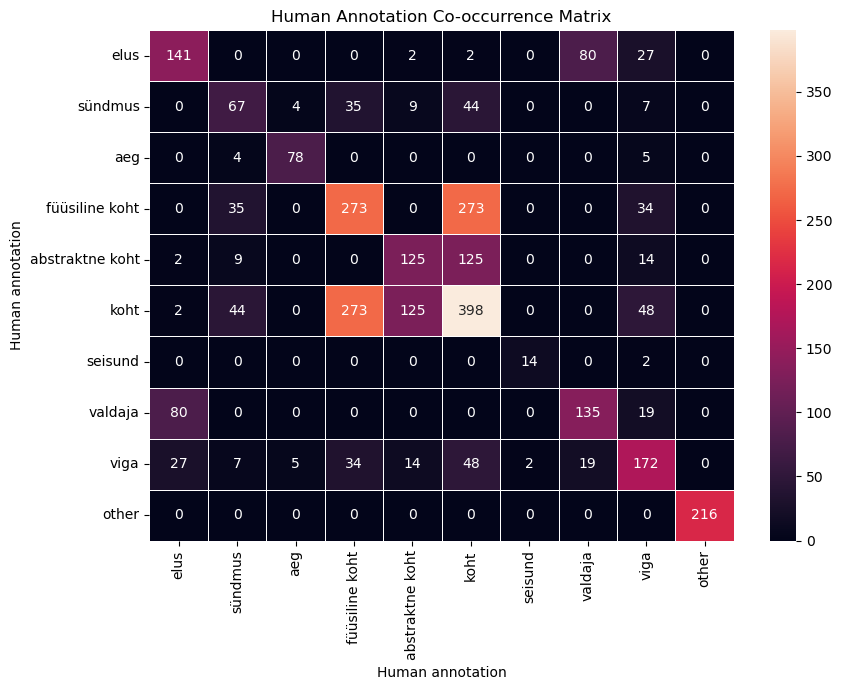

In [24]:
# Plot heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    human_cm,
    annot=True,
    fmt='d',
    linewidths=0.5
)

plt.xlabel('Human annotation')
plt.ylabel('Human annotation')
plt.title('Human Annotation Co-occurrence Matrix')

plt.tight_layout()
plt.show()